In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C2"
DTYPE="GLCM"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C2_10,27,"[DATA/TRAINING/C2/C2_10/IMG_6566.HEIC, DATA/TR..."
1,C2_11,25,"[DATA/TRAINING/C2/C2_11/IMG_6666.HEIC, DATA/TR..."
2,C2_12,25,"[DATA/TRAINING/C2/C2_12/IMG_6789.HEIC, DATA/TR..."
3,C2_13,29,"[DATA/TRAINING/C2/C2_13/IMG_6944.HEIC, DATA/TR..."
4,C2_14,25,"[DATA/TRAINING/C2/C2_14/IMG_7189.HEIC, DATA/TR..."
5,C2_15,28,"[DATA/TRAINING/C2/C2_15/IMG_7315.HEIC, DATA/TR..."
6,C2_16,28,"[DATA/TRAINING/C2/C2_16/IMG_7447.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_7482.HEIC')

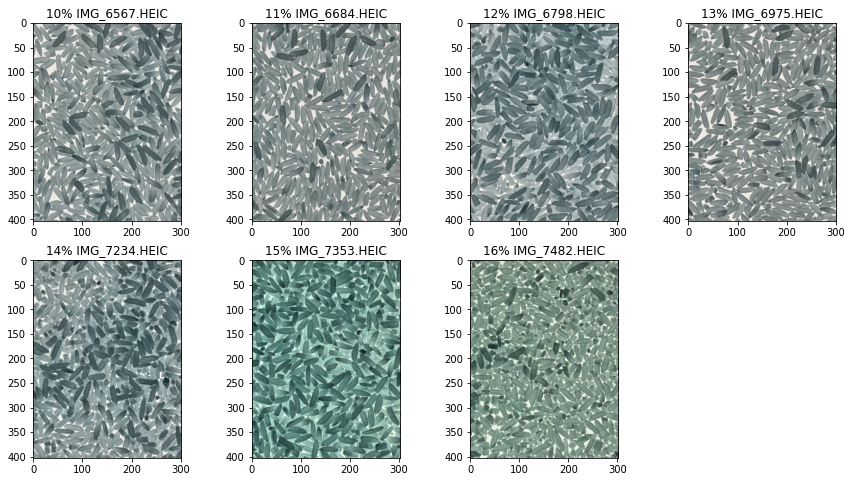

In [11]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [18]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [19]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,180.850173,300.364603,188.572317,336.415353,6.465713,8.300906,6.654251,8.846602,0.265282,0.224473,...,0.000491,0.000395,0.000473,0.000381,25,1008,756,3,IMG_6566.HEIC,10
1,223.631295,347.155905,204.950391,389.324994,7.095484,8.781101,6.795767,9.383020,0.259707,0.225817,...,0.000600,0.000505,0.000610,0.000479,25,1008,756,3,IMG_6567.HEIC,10
2,229.422698,388.541118,193.526517,342.618835,7.180800,9.369989,6.574693,8.747142,0.261848,0.219668,...,0.000668,0.000538,0.000698,0.000566,25,1008,756,3,IMG_6568.HEIC,10
3,211.138793,331.830741,200.343691,374.397771,6.924804,8.622013,6.773155,9.233810,0.261359,0.227705,...,0.000600,0.000503,0.000604,0.000478,25,1008,756,3,IMG_6569.HEIC,10
4,248.162910,392.107616,191.471759,374.758833,7.364618,9.334635,6.500095,9.178278,0.259208,0.219158,...,0.000718,0.000587,0.000773,0.000590,25,1008,756,3,IMG_6570.HEIC,10
5,216.415441,367.278578,189.930485,342.801872,6.814531,9.082828,6.513767,8.699592,0.273651,0.223765,...,0.000606,0.000470,0.000607,0.000484,25,1008,756,3,IMG_6571.HEIC,10
6,258.065183,409.338752,198.925327,387.299652,7.474712,9.484145,6.516320,9.239256,0.260335,0.219459,...,0.000765,0.000619,0.000829,0.000630,25,1008,756,3,IMG_6572.HEIC,10
7,201.246040,347.172448,199.592530,349.507239,6.753816,8.957169,6.769484,8.941859,0.266677,0.220338,...,0.000572,0.000451,0.000563,0.000454,25,1008,756,3,IMG_6573.HEIC,10
8,221.538191,375.001713,200.532575,353.387905,7.047657,9.268249,6.744877,8.915658,0.258425,0.214616,...,0.000571,0.000455,0.000579,0.000469,25,1008,756,3,IMG_6574.HEIC,10
9,204.019883,350.953181,210.520360,369.109519,6.709290,8.896836,6.883062,9.115157,0.269404,0.224493,...,0.000581,0.000459,0.000563,0.000453,25,1008,756,3,IMG_6575.HEIC,10


# Classification

In [157]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [158]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [159]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [160]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [161]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [162]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.473684,0.580952,0.476190,0.523381,GLCM,C2,RF_C,3,120,90,3
1,2,0.578947,0.657143,0.571429,0.611296,GLCM,C2,RF_C,3,120,90,3
2,3,0.684211,0.742857,0.642857,0.689249,GLCM,C2,RF_C,3,120,90,3
3,4,0.421053,0.557143,0.404762,0.468883,GLCM,C2,RF_C,3,120,90,3
4,5,0.736842,0.702381,0.714286,0.708283,GLCM,C2,RF_C,3,120,90,3
5,6,0.526316,0.476190,0.500000,0.487805,GLCM,C2,RF_C,3,120,90,3
6,7,0.684211,0.750000,0.714286,0.731707,GLCM,C2,RF_C,3,120,90,3
7,8,0.555556,0.580952,0.547619,0.563793,GLCM,C2,RF_C,3,120,90,3
8,9,0.555556,0.523810,0.571429,0.546584,GLCM,C2,RF_C,3,120,90,3
9,10,0.777778,0.761905,0.761905,0.761905,GLCM,C2,RF_C,3,120,90,3


In [163]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C2,RF_C,0.599415,0.590476,0.609289,0.633333


### MLP Classifier

In [164]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [165]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [166]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.473684,0.440476,0.452381,0.446349,GLCM,C2,MLP_C,3,120,90,3
1,2,0.473684,0.619048,0.476190,0.538302,GLCM,C2,MLP_C,3,120,90,3
2,3,0.578947,0.678571,0.571429,0.620408,GLCM,C2,MLP_C,3,120,90,3
3,4,0.631579,0.690476,0.642857,0.665816,GLCM,C2,MLP_C,3,120,90,3
4,5,0.684211,0.726190,0.642857,0.681988,GLCM,C2,MLP_C,3,120,90,3
5,6,0.526316,0.535714,0.476190,0.504202,GLCM,C2,MLP_C,3,120,90,3
6,7,0.631579,0.719048,0.619048,0.665311,GLCM,C2,MLP_C,3,120,90,3
7,8,0.611111,0.791667,0.571429,0.663755,GLCM,C2,MLP_C,3,120,90,3
8,9,0.666667,0.738095,0.666667,0.700565,GLCM,C2,MLP_C,3,120,90,3
9,10,0.722222,0.788095,0.738095,0.762276,GLCM,C2,MLP_C,3,120,90,3


In [167]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C2,MLP_C,0.6,0.585714,0.624897,0.672738


### XGBoost Classifier

In [168]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [169]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.421053,0.476190,0.428571,0.451128,GLCM,C2,XGB_C,3,120,90,3
1,2,0.578947,0.583333,0.571429,0.577320,GLCM,C2,XGB_C,3,120,90,3
2,3,0.684211,0.714286,0.690476,0.702179,GLCM,C2,XGB_C,3,120,90,3
3,4,0.578947,0.595238,0.547619,0.570437,GLCM,C2,XGB_C,3,120,90,3
4,5,0.578947,0.692857,0.547619,0.611736,GLCM,C2,XGB_C,3,120,90,3
5,6,0.578947,0.716667,0.571429,0.635860,GLCM,C2,XGB_C,3,120,90,3
6,7,0.526316,0.583333,0.523810,0.551971,GLCM,C2,XGB_C,3,120,90,3
7,8,0.500000,0.500000,0.523810,0.511628,GLCM,C2,XGB_C,3,120,90,3
8,9,0.333333,0.380952,0.380952,0.380952,GLCM,C2,XGB_C,3,120,90,3
9,10,0.555556,0.547619,0.547619,0.547619,GLCM,C2,XGB_C,3,120,90,3


In [170]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C2,XGB_C,0.533626,0.533333,0.554083,0.579048


# External validation

In [171]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C2_10,5,"[DATA/TEST/C2/C2_10/IMG_6560.HEIC, DATA/TEST/C..."
1,C2_11,5,"[DATA/TEST/C2/C2_11/IMG_6656.HEIC, DATA/TEST/C..."
2,C2_12,5,"[DATA/TEST/C2/C2_12/IMG._6813.HEIC, DATA/TEST/..."
3,C2_13,5,"[DATA/TEST/C2/C2_13/IMG_6918.HEIC, DATA/TEST/C..."
4,C2_14,5,"[DATA/TEST/C2/C2_14/IMG_7179.HEIC, DATA/TEST/C..."
5,C2_15,5,"[DATA/TEST/C2/C2_15/IMG_7305.HEIC, DATA/TEST/C..."
6,C2_16,5,"[DATA/TEST/C2/C2_16/IMG_7437.HEIC, DATA/TEST/C..."


In [172]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [173]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])

        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [174]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,705.109551,1003.019356,761.376190,1115.072703,17.961610,22.313851,19.064893,23.941176,0.090517,0.071126,...,0.000257,0.000223,0.000245,0.000212,3,120,90,3,IMG_6560.HEIC,10
1,609.975468,923.768199,728.100934,1032.248891,16.677341,21.337079,18.467320,23.024266,0.094990,0.069656,...,0.000284,0.000239,0.000262,0.000226,3,120,90,3,IMG_6561.HEIC,10
2,709.423502,1065.452460,762.247899,1077.394203,18.220880,23.109338,19.012418,23.646681,0.090073,0.066568,...,0.000255,0.000217,0.000248,0.000211,3,120,90,3,IMG_6563.HEIC,10
3,683.243539,1169.078935,785.100654,984.836087,17.921067,24.967520,19.680299,22.267302,0.085946,0.054570,...,0.000268,0.000214,0.000253,0.000230,3,120,90,3,IMG_6564.HEIC,10
4,694.987828,1029.748843,761.288422,1091.806439,17.860674,22.787272,18.874603,23.432726,0.091071,0.071052,...,0.000256,0.000217,0.000241,0.000209,3,120,90,3,IMG_6565.HEIC,10
0,774.830618,997.635068,751.640243,1149.381078,18.998970,21.734964,18.469188,24.235577,0.087885,0.080346,...,0.000328,0.000313,0.000340,0.000272,3,120,90,3,IMG_6656.HEIC,11
1,769.108989,1004.503163,752.287768,1150.167312,18.594195,21.694930,18.231186,23.776603,0.091521,0.083320,...,0.000352,0.000322,0.000364,0.000292,3,120,90,3,IMG_6658.HEIC,11
2,820.036891,887.408460,652.589262,1232.301860,19.721161,20.371920,17.144258,25.251345,0.082921,0.083668,...,0.000273,0.000272,0.000309,0.000233,3,120,90,3,IMG_6660.HEIC,11
3,899.389232,1192.458691,784.371989,1200.827212,20.418633,23.882353,18.550327,24.222547,0.085145,0.073777,...,0.000319,0.000290,0.000352,0.000286,3,120,90,3,IMG_6661.HEIC,11
4,770.836704,1181.035124,748.057983,1021.168350,18.969476,24.594561,18.345752,22.254745,0.089454,0.063412,...,0.000262,0.000219,0.000272,0.000233,3,120,90,3,IMG_6664.HEIC,11


In [175]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [176]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [177]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [178]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [179]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.17      0.20      0.18         5
     Class 1       0.00      0.00      0.00         5
     Class 2       0.56      1.00      0.71         5
     Class 3       1.00      0.60      0.75         5
     Class 4       0.43      0.60      0.50         5
     Class 5       0.25      0.20      0.22         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.49        35
   macro avg       0.49      0.49      0.47        35
weighted avg       0.49      0.49      0.47        35



## MLP

In [180]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [181]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.20      0.20      0.20         5
     Class 1       1.00      0.40      0.57         5
     Class 2       0.43      0.60      0.50         5
     Class 3       0.83      1.00      0.91         5
     Class 4       0.50      0.80      0.62         5
     Class 5       0.00      0.00      0.00         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.57        35
   macro avg       0.57      0.57      0.54        35
weighted avg       0.57      0.57      0.54        35



## XGBC

In [182]:
y_pred = modelXGBC.predict(X_test_scale) 

In [183]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       0.50      0.20      0.29         5
     Class 2       0.50      1.00      0.67         5
     Class 3       0.57      0.80      0.67         5
     Class 4       0.33      0.40      0.36         5
     Class 5       0.33      0.40      0.36         5
     Class 6       1.00      0.60      0.75         5

    accuracy                           0.49        35
   macro avg       0.46      0.49      0.44        35
weighted avg       0.46      0.49      0.44        35

